In [57]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

# configurações de visual
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.family'] = 'sans-serif'
sns.set_theme(style='whitegrid')

# conexão
conn = sqlite3.connect('../data/olist.db')

print('Bibliotecas carregadas!')

Bibliotecas carregadas!


In [58]:
# carregando as tabelas principais
orders = pd.read_sql('SELECT * FROM orders', conn)
order_items = pd.read_sql('SELECT * FROM order_items', conn)
customers = pd.read_sql('SELECT * FROM customers', conn)
products = pd.read_sql('SELECT * FROM products', conn)
sellers = pd.read_sql('SELECT * FROM sellers', conn)
order_reviews = pd.read_sql('SELECT * FROM order_reviews', conn)
order_payments = pd.read_sql('SELECT * FROM order_payments', conn)

print('DataFrames carregados!')
print(f'orders: {orders.shape}')
print(f'order_items: {order_items.shape}')
print(f'customers: {customers.shape}')
print(f'products: {products.shape}')
print(f'sellers: {sellers.shape}')
print(f'order_reviews: {order_reviews.shape}')
print(f'order_payments: {order_payments.shape}')

DataFrames carregados!
orders: (99441, 8)
order_items: (112650, 7)
customers: (99441, 5)
products: (32951, 9)
sellers: (3095, 4)
order_reviews: (99224, 7)
order_payments: (103886, 5)


In [59]:
# inspeção inicial
print('=== ORDERS ===')
print(orders.dtypes)
print('\nNulos por coluna:')
print(orders.isnull().sum())

=== ORDERS ===
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

Nulos por coluna:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [60]:
colunas_data = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in colunas_data:
    orders[col] = pd.to_datetime(orders[col])

print(orders.dtypes)
print(f'\nShape: {orders.shape}')

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

Shape: (99441, 8)


In [61]:
df_main = (orders
    .merge(order_items, on='order_id', how='left')
    .merge(customers, on='customer_id', how='left')
    .merge(products, on='product_id', how='left')
    .merge(sellers, on='seller_id', how='left')
)

print(f'Shape: {df_main.shape}')
print(f'Colunas: {list(df_main.columns)}')

Shape: (113425, 29)
Colunas: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'seller_zip_code_prefix', 'seller_city', 'seller_state']


In [62]:
df_main['mes_compra'] = df_main['order_purchase_timestamp'].dt.to_period('M')
df_main['ano_compra'] = df_main['order_purchase_timestamp'].dt.year
df_main['dia_semana'] = df_main['order_purchase_timestamp'].dt.day_name()

df_main['tempo_entrega_dias'] = (
    df_main['order_delivered_customer_date'] -
    df_main['order_purchase_timestamp']
).dt.days

df_entregues = df_main[df_main['order_status'] == 'delivered'].copy()

print(f'Total de pedidos: {len(df_main)}')
print(f'Pedidos entregues: {len(df_entregues)}')
print(f'Taxa de entrega: {len(df_entregues)/len(df_main)*100:.1f}%')

Total de pedidos: 113425
Pedidos entregues: 110197
Taxa de entrega: 97.2%


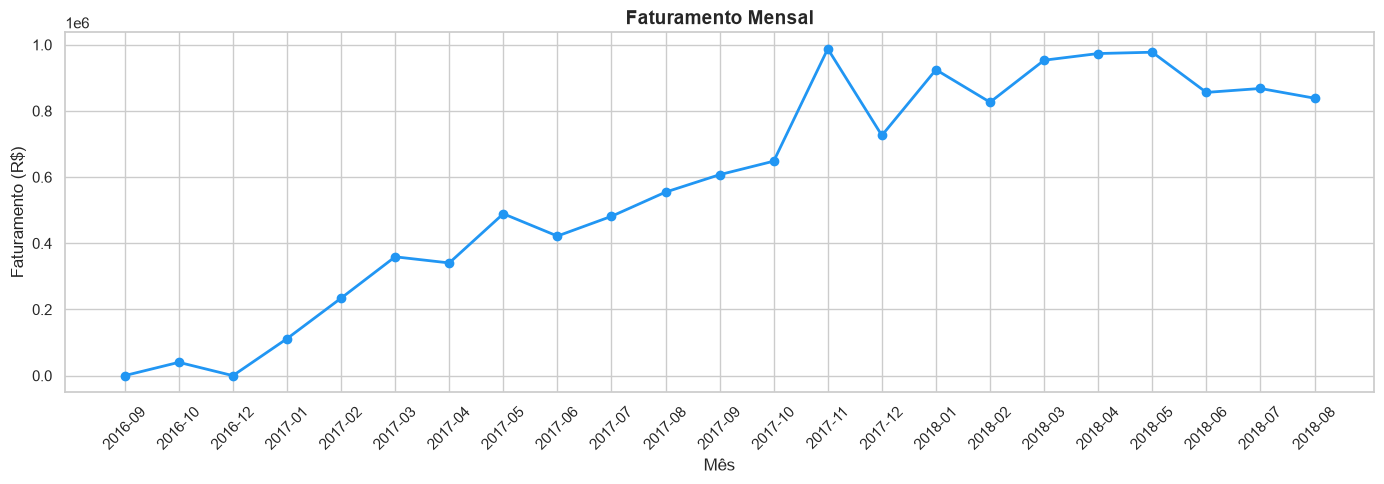

In [63]:
# Gráfico 1: Faturamento mensal
faturamento_mensal = (df_entregues
    .groupby('mes_compra')['price']
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 5))
plt.plot(
    faturamento_mensal['mes_compra'].astype(str), 
    faturamento_mensal['price'], 
    marker='o', linewidth=2, color='#2196F3'
)
plt.title('Faturamento Mensal', fontsize=14, fontweight='bold')
plt.xlabel('Mês')
plt.ylabel('Faturamento (R$)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../outputs/faturamento_mensal.png', dpi=150)
plt.show()

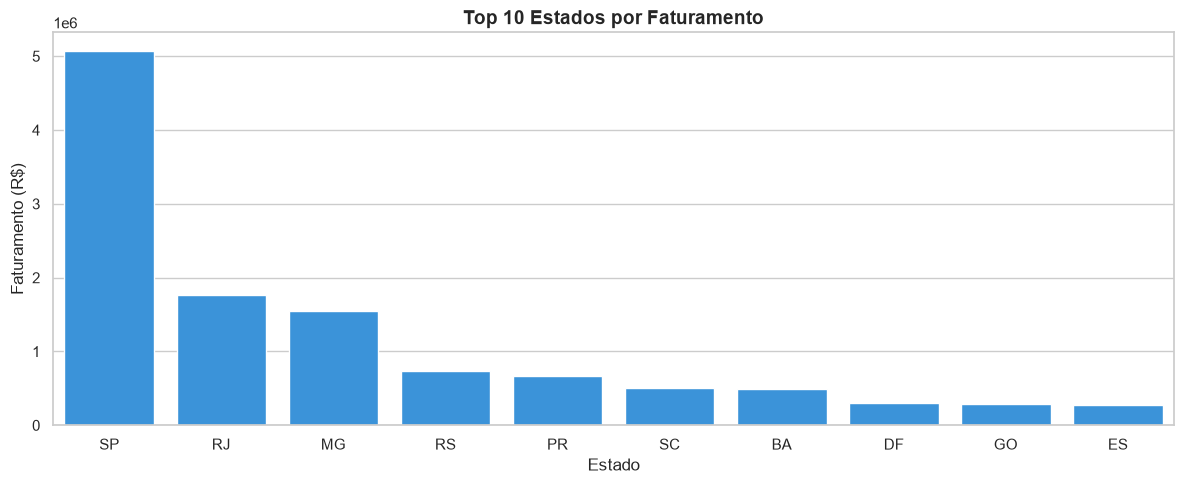

In [64]:
# Gráfico 2: Top 10 estados por faturamento
fat_estado = (df_entregues
    .groupby('customer_state')['price']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 5))
sns.barplot(data=fat_estado, x='customer_state', y='price', color='#2196F3')
plt.title('Top 10 Estados por Faturamento', fontsize=14, fontweight='bold')
plt.xlabel('Estado')
plt.ylabel('Faturamento (R$)')
plt.tight_layout()
plt.savefig('../outputs/faturamento_estado.png', dpi=150)
plt.show()

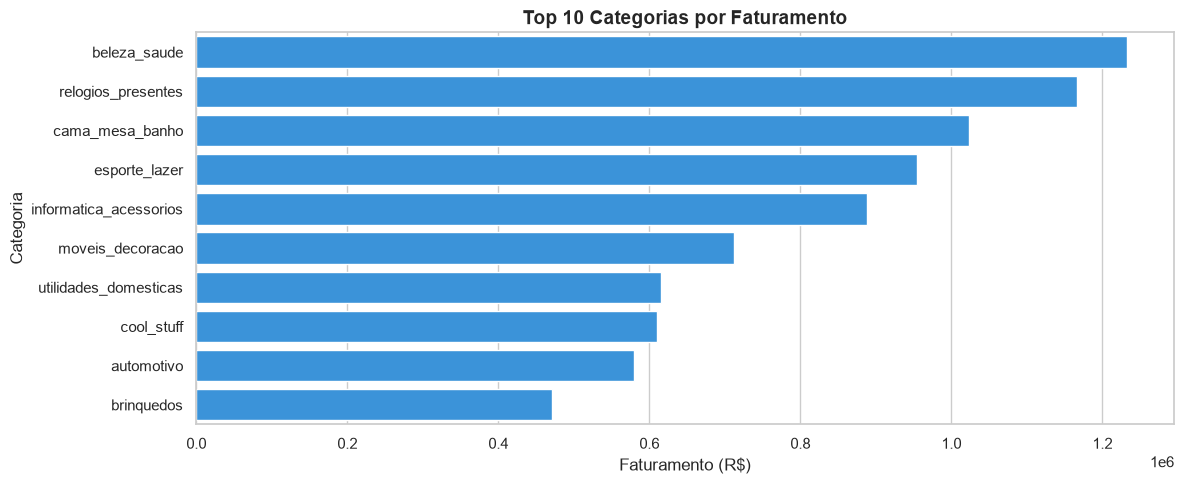

In [65]:
# Gráfico 3: Top 10 categorias por faturamento
fat_categoria = (df_entregues
    .groupby('product_category_name')['price']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 5))
sns.barplot(data=fat_categoria, x='price', y='product_category_name', color='#2196F3')
plt.title('Top 10 Categorias por Faturamento', fontsize=14, fontweight='bold')
plt.xlabel('Faturamento (R$)')
plt.ylabel('Categoria')
plt.tight_layout()
plt.savefig('../outputs/faturamento_categoria.png', dpi=150)
plt.show()

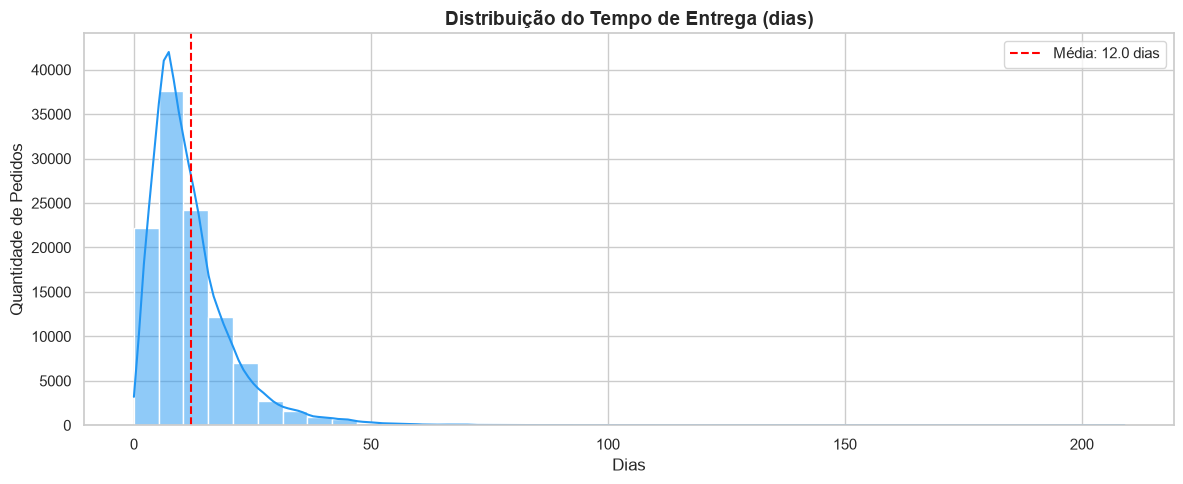

In [66]:
# Gráfico 4: Distribuição do tempo de entrega
plt.figure(figsize=(12, 5))
sns.histplot(
    df_entregues['tempo_entrega_dias'].dropna(), 
    bins=40, color='#2196F3', kde=True
)
plt.title('Distribuição do Tempo de Entrega (dias)', fontsize=14, fontweight='bold')
plt.xlabel('Dias')
plt.ylabel('Quantidade de Pedidos')

plt.axvline(df_entregues['tempo_entrega_dias'].mean(), 
            color='red', linestyle='--', label=f"Média: {df_entregues['tempo_entrega_dias'].mean():.1f} dias")
plt.legend()
plt.tight_layout()
plt.savefig('../outputs/tempo_entrega.png', dpi=150)
plt.show()

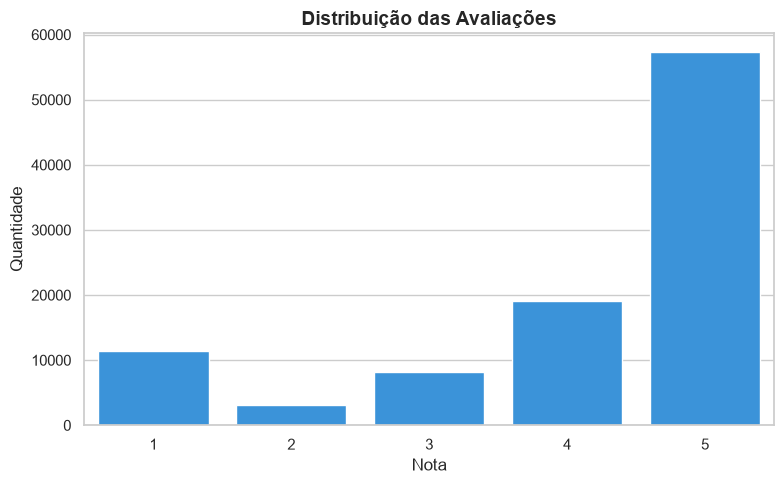

In [67]:
# Gráfico 5: Distribuição das avaliações
avaliacoes = order_reviews['review_score'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x=avaliacoes.index, y=avaliacoes.values, color='#2196F3')
plt.title('Distribuição das Avaliações', fontsize=14, fontweight='bold')
plt.xlabel('Nota')
plt.ylabel('Quantidade')
plt.tight_layout()
plt.savefig('../outputs/avaliacoes.png', dpi=150)
plt.show()